**1️⃣ Import Libraries**

In [ ]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

**2️⃣ Load Twitter Dataset**

In [ ]:
profiles = pd.read_excel("twitter_sna_dataset_2sheets_600users.xlsx", sheet_name="profiles")
edges = pd.read_excel("twitter_sna_dataset_2sheets_600users.xlsx", sheet_name="interactions")

print(profiles)
print(edges)

     username  followers  following  tweets  likes  retweets  replies
0      user_1     122058       2836    2818   3911      3291     3180
1      user_2     146967       1172    2636   3389      7504     1910
2      user_3     132032       4129    1297  13629      1246     1012
3      user_4     103794       1621    2153   2430      3719     3604
4      user_5     119979       2193    1121    458      3839      669
..        ...        ...        ...     ...    ...       ...      ...
595  user_596      44525        882    2066   5439      6957     2043
596  user_597      38856       4458    2831  14473      3958     2248
597  user_598      18988       2856    2280   9765      7183     2416
598  user_599     166907       2540    1449  13279      5248      796
599  user_600      47395        377     562   6511       574       76

[600 rows x 7 columns]
     source_user target_user interaction_type
0        user_59    user_339           follow
1       user_431    user_556            repl

**3️⃣ Build Network Graph**

In [ ]:
G = nx.from_pandas_edgelist(
    edges,
    source="source_user",
    target="target_user"
)

print("Total Nodes:", G.number_of_nodes())
print("Total Edges:", G.number_of_edges())

Total Nodes: 600
Total Edges: 2974


**4️⃣ Calculate Centrality Measures**

In [ ]:
degree = nx.degree_centrality(G)
betweenness = nx.betweenness_centrality(G)
closeness = nx.closeness_centrality(G)
eigenvector = nx.eigenvector_centrality(G, max_iter=1000)

**5️⃣ Convert Results to DataFrame**

In [ ]:
centrality_df = pd.DataFrame({
    "username": list(degree.keys()),
    "degree": list(degree.values()),
    "betweenness": list(betweenness.values()),
    "closeness": list(closeness.values()),
    "eigenvector": list(eigenvector.values())
})

print(centrality_df.head())

   username    degree  betweenness  closeness  eigenvector
0   user_59  0.025042     0.007038   0.351732     0.054426
1  user_339  0.016694     0.003062   0.339569     0.041035
2  user_431  0.015025     0.002857   0.329483     0.031633
3  user_556  0.020033     0.005002   0.339185     0.040139
4  user_500  0.015025     0.002699   0.339762     0.044488


**6️⃣ Calculate Influence Score**

In [ ]:
centrality_df["rank_score"] = (
    centrality_df["degree"] +
    centrality_df["betweenness"] +
    centrality_df["closeness"] +
    centrality_df["eigenvector"]
)

**7️⃣ Find Top Influencers**

In [ ]:
top_influencers = centrality_df.sort_values(
    by="rank_score",
    ascending=False
).head(10)

print(top_influencers)

     username    degree  betweenness  closeness  eigenvector  rank_score
53   user_387  0.033389     0.013201   0.372976     0.089256    0.508823
222  user_528  0.031720     0.011625   0.371128     0.083024    0.497496
302  user_237  0.031720     0.010270   0.367259     0.086564    0.495813
510   user_73  0.031720     0.010619   0.369297     0.082320    0.493955
507  user_439  0.031720     0.010724   0.363913     0.075257    0.481612
12    user_69  0.028381     0.008101   0.363471     0.076655    0.476607
63   user_271  0.030050     0.008749   0.362152     0.074676    0.475627
562  user_538  0.025042     0.006256   0.364134     0.079047    0.474479
217  user_573  0.028381     0.009128   0.362591     0.073122    0.473221
98   user_558  0.030050     0.011270   0.362810     0.068591    0.472722


**8️⃣ Plot Network Graph**

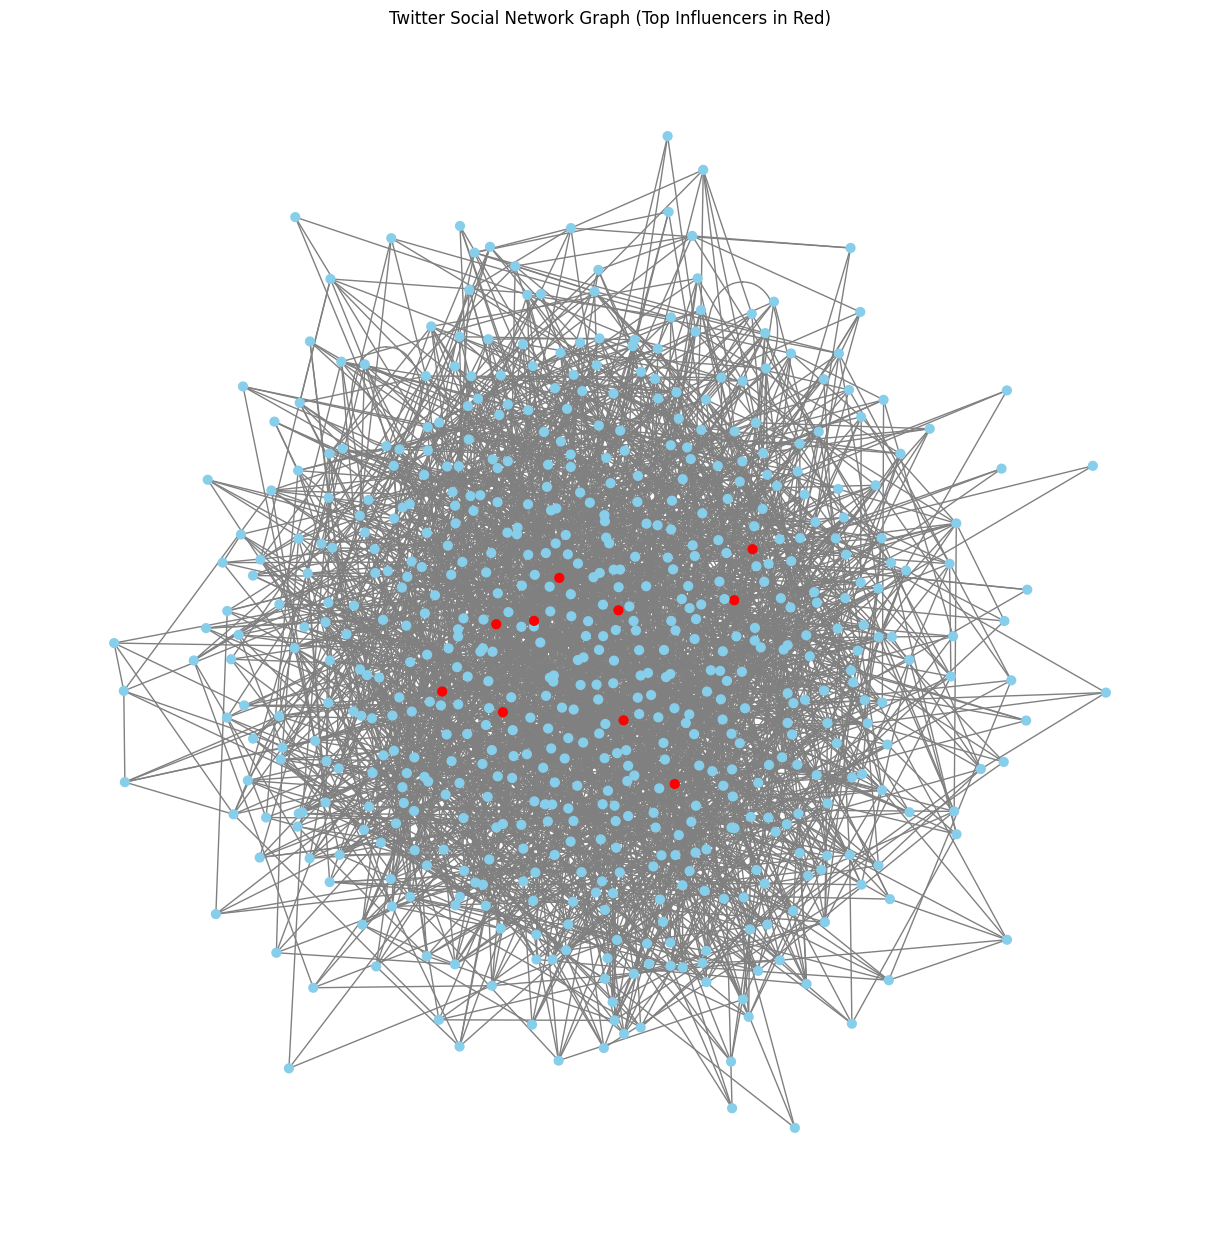

In [ ]:
top_users = list(top_influencers["username"])

plt.figure(figsize=(12,12))

pos = nx.spring_layout(G)

node_colors = []

for node in G.nodes():
    if node in top_users:
        node_colors.append("red")
    else:
        node_colors.append("skyblue")

nx.draw(
    G,
    pos,
    node_size=40,
    node_color=node_colors,
    edge_color="gray",
    with_labels=False
)

plt.title("Twitter Social Network Graph (Top Influencers in Red)")
plt.show()

**9️⃣ Save Results to Excel**

In [ ]:
centrality_df.to_excel("twitter_influencer_results.xlsx", index=False)

**Feature-1: Sentiment Analysis**

In [ ]:
good_comments = [
"Great content!",
"Very informative",
"Excellent post",
"Really enjoyed this",
"Amazing work",
"Very useful information",
"Love this",
"Keep it up",
"Fantastic content",
"Very interesting"
]

bad_comments = [
"This is terrible",
"I don't like this",
"Waste of time",
"Very bad content",
"Not useful at all",
"Poor explanation",
"This is boring",
"Very disappointing",
"I hate this",
"Very confusing"
]

In [ ]:
import pandas as pd
import random

file = "twitter_sna_dataset_2sheets_600users.xlsx"

profiles = pd.read_excel(file, sheet_name="profiles")
edges = pd.read_excel(file, sheet_name="interactions")

edges["comment_text"] = ""

for i in range(len(edges)):
    if edges.loc[i,"interaction_type"] == "reply":
        edges.loc[i,"comment_text"] = random.choice(good_comments + bad_comments)

with pd.ExcelWriter("twitter_sentiment_dataset.xlsx") as writer:
    profiles.to_excel(writer, sheet_name="profiles", index=False)
    edges.to_excel(writer, sheet_name="interactions", index=False)

**Method: Sentiment Analysis Using TextBlob
Step 1: Install Library**

In [ ]:
!pip install textblob

**Step 2: Load Dataset**

In [ ]:
import pandas as pd

edges = pd.read_excel("twitter_sentiment_dataset.xlsx", sheet_name="interactions")

edges.head()

,source_user,target_user,interaction_type,comment_text
0,user_59,user_339,follow,NaN
1,user_431,user_556,reply,Not useful at all
2,user_500,user_509,reply,Waste of time
3,user_109,user_238,retweet,NaN
4,user_278,user_134,follow,NaN


**Step 3: Perform Sentiment Analysis**

In [ ]:
from textblob import TextBlob

def analyze_sentiment(text):

    if text == "" or pd.isna(text):
        return "No Comment"

    polarity = TextBlob(text).sentiment.polarity

    if polarity > 0:
        return "Positive"
    else:
        return "Negative"


edges["predicted_sentiment"] = edges["comment_text"].apply(analyze_sentiment)

**Step 4: See Results**

In [ ]:
edges[["comment_text","predicted_sentiment"]].head(10)

,comment_text,predicted_sentiment
0,NaN,No Comment
1,Not useful at all,Negative
2,Waste of time,Negative
3,NaN,No Comment
4,NaN,No Comment
5,NaN,No Comment
6,NaN,No Comment
7,Very useful information,Positive
8,NaN,No Comment
9,Fantastic content,Positive


**Step 5: Count Positive vs Negative Comments**

In [ ]:
edges["predicted_sentiment"].value_counts()

,count
predicted_sentiment,
No Comment,2294
Negative,360
Positive,346


**Step 6: Visualization**

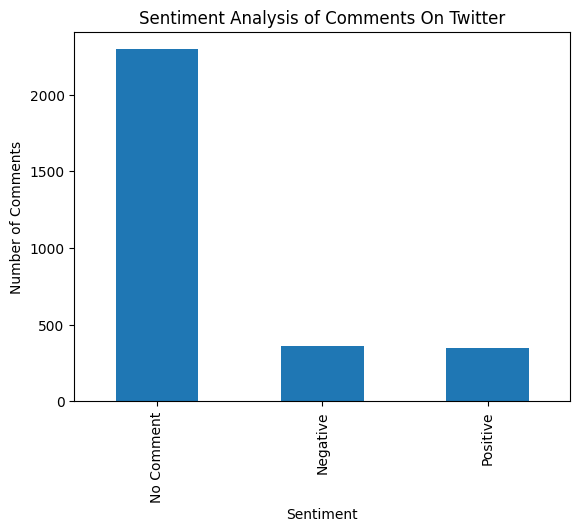

In [ ]:
import matplotlib.pyplot as plt

edges["predicted_sentiment"].value_counts().plot(kind="bar")

plt.title("Sentiment Analysis of Comments On Twitter")
plt.xlabel("Sentiment")
plt.ylabel("Number of Comments")

plt.show()

**Feature-2: BOT/FAKE Account Detection**

In [ ]:
import pandas as pd

In [ ]:
# Load nodes sheet (user data)
df = pd.read_excel("twitter_sna_dataset_2sheets_600users.xlsx", sheet_name="profiles")

df.head()

,username,followers,following,tweets,likes,retweets,replies
0,user_1,122058,2836,2818,3911,3291,3180
1,user_2,146967,1172,2636,3389,7504,1910
2,user_3,132032,4129,1297,13629,1246,1012
3,user_4,103794,1621,2153,2430,3719,3604
4,user_5,119979,2193,1121,458,3839,669


In [ ]:
def bot_score(row):
    score = 0

    # Rule 1: Following >> Followers
    if row['following'] > 1000:
        score += 1

    if row['followers'] < 100:
        score += 1

    # Rule 2: High posting activity
    if row['posts'] > 300:
        score += 1

    # Rule 3: Low influence (if centrality exists)
    if 'eigenvector' in row and row['eigenvector'] < 0.01:
        score += 1

    return score

In [ ]:
# Corrected bot_score function definition for this cell
def bot_score(row):
    score = 0

    # Rule 1: Following >> Followers
    if row['following'] > 1000:
        score += 1

    if row['followers'] < 100:
        score += 1

    # Rule 2: High posting activity (corrected from 'posts' to 'tweets')
    if row['tweets'] > 300:
        score += 1

    # Rule 3: Low influence (if centrality exists)
    # This check ensures no KeyError if 'eigenvector' is not present in the row
    if 'eigenvector' in row and row['eigenvector'] < 0.01:
        score += 1

    return score

profiles["bot_score"] = profiles.apply(bot_score, axis=1)

profiles["account_type"] = profiles["bot_score"].apply(
    lambda x: "Bot" if x >= 2 else "Real User"
)


In [ ]:
print(profiles["account_type"].value_counts())

account_type
Bot          449
Real User    151
Name: count, dtype: int64


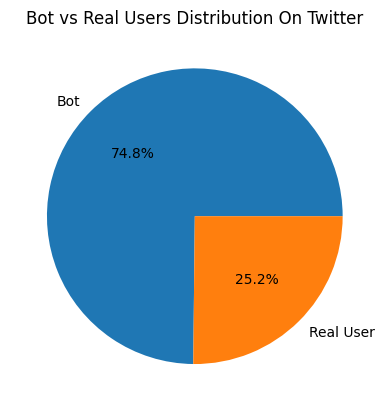

In [ ]:
import matplotlib.pyplot as plt

profiles["account_type"].value_counts().plot(kind="pie", autopct="%1.1f%%")

plt.title("Bot vs Real Users Distribution On Twitter")
plt.ylabel("")

plt.show()